<a href="https://colab.research.google.com/github/finnesaa/Data-Analytics-Project-1/blob/main/Project2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd

Data set: https://www.kaggle.com/datasets/saquib7hussain/experience-salary-dataset

This dataset contains information of work experience(in months)and salary(in thousand dollars) from employees of various indusrties. The data set consits of 2 columns and 1000 rows. The target variable is salary(in thousands). The goal of the project is to develop a machine learning model that predicts an employee's salary based on their experience. In this case, linear regreession is the best option since th epurpose is to predict how one variable changes in response to another. This methods is popular in businees since it is straightforward.

In [ ]:
df = pd.read_csv('Experience-Salary.csv')

In [ ]:
#shape
print("shape",df.shape)

shape (1000, 2)


In [ ]:
#column headers
print("Column Headers\n", df.columns.tolist())

Column Headers
 ['exp(in months)', 'salary(in thousands)']


In [ ]:
#data types
print(df.dtypes)

exp(in months)          float64
salary(in thousands)    float64
dtype: object


In [ ]:
#first 20 rows of data
print(df.head(20))

    exp(in months)  salary(in thousands)
0        18.290293             16.521825
1        17.023407             11.666234
2        26.343613             23.167255
3        19.105834             20.877145
4        27.742516             23.166236
5        31.671171             32.966251
6        14.186399             15.294170
7        29.932845             33.159461
8        32.841327             32.032653
9        26.873869             32.347784
10       41.513808             38.246876
11       32.201178             22.773603
12       34.738226             39.554841
13       27.514931             26.922870
14       25.761258             28.116477
15       36.925318             32.533003
16       23.747002             26.043332
17       24.093488             24.086041
18       16.133802             20.919911
19       23.252563             21.041636


In [ ]:
#last 20 rows of data
print(df.tail(20))

     exp(in months)  salary(in thousands)
980       23.679336             19.440756
981       25.170273             26.073939
982       38.320404             35.240232
983       23.534460             22.302274
984       43.780644             40.351157
985       28.520992             38.138390
986       24.953138             33.568944
987       24.876543             24.974932
988       28.846048             21.655540
989       45.724595             46.605938
990       20.674496             27.889743
991       26.411099             27.551955
992       36.843395             28.476800
993       17.584566             12.404925
994       21.894199             17.584261
995       22.161741             24.666502
996       32.266497             24.160270
997       17.039030             19.903797
998       25.222124             21.974413
999       16.418028             19.634787


In [11]:
#check for missing values
print(df.isnull().sum())

exp(in months)          0
salary(in thousands)    0
dtype: int64


In [12]:
#check for duplicates
print(df.duplicated().sum())

0


In [ ]:
#setting up variables
X = df[['exp(in months)']]
Y = df['salary(in thousands)']

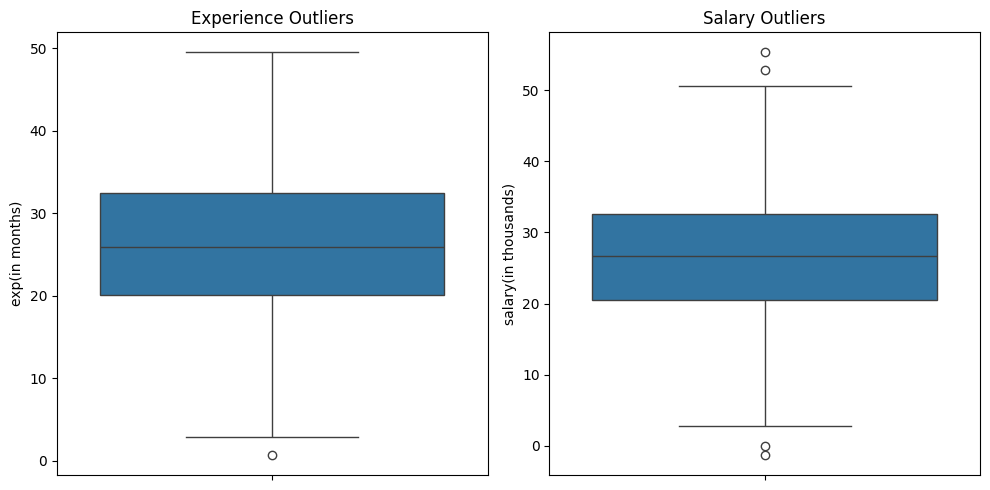

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

#using a boxplot to find outliers in the data set
plt.figure(figsize=(10, 5))

plt.subplot(1, 2, 1)
sns.boxplot(y=df['exp(in months)'])
plt.title('Experience Outliers')

plt.subplot(1, 2, 2)
sns.boxplot(y=df['salary(in thousands)'])
plt.title('Salary Outliers')

plt.tight_layout()
plt.show()

The boxplots show 5 potential outliers in the data set. There is one in experience and one in salary. The only outliers to be concerned with are the negative values found in salary since they are not realistic. The other two outliers in the salary column aren't necessarily errors.

In [13]:
#find negative values in salary
print(df[df['salary(in thousands)'] < 0])

     exp(in months)  salary(in thousands)
133        8.520651             -1.276342
772        2.882022             -0.074563


In [ ]:
#remove negative values
df = df[df['salary(in thousands)'] >= 0]

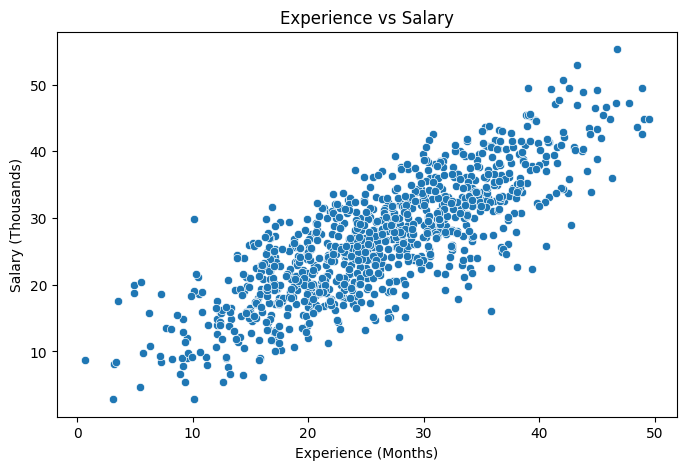

In [ ]:
#scatterplot to examine relationship between experience and salary
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x='exp(in months)',
    y='salary(in thousands)'
)

plt.title('Experience vs Salary')
plt.xlabel('Experience (Months)')
plt.ylabel('Salary (Thousands)')
plt.show()

The scattter plot shows how salary increases as experience increases. There is a strong positive correlation.

In [16]:
#analyze correlation
correlation = df.corr()

print(correlation)

                      exp(in months)  salary(in thousands)
exp(in months)              1.000000              0.810969
salary(in thousands)        0.810969              1.000000


For this specific dataset an ANOVA and Chi-squared test is not necessary. ANOVA tests are used for variance. It analyzes the differences among means in a sample. If we  had several categories like occupation or education level, an ANOVA test would be useful.

Like the ANOVA test, the Chi-squared test requires categorical variables in order to be meaningfully used.

The best tools to use for this dataset is linear regression and correlation.



In [14]:
#check variance
print(df.var())

exp(in months)          75.987678
salary(in thousands)    78.229792
dtype: float64


This dataset shows unique values in each column and neither has zero variance, which is extremely useful for making predictions.

In [ ]:
#build prediction model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_score
import numpy as np


X = df[['exp(in months)']]
y = df['salary(in thousands)']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = LinearRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("R-squared:", r2_score(y_test, y_pred))
print("MAE:", mean_absolute_error(y_test, y_pred))
print("RMSE:", np.sqrt(mean_squared_error(y_test, y_pred)))


cv_scores = cross_val_score(
    model, X, y, cv=5, scoring='r2'
)

print("Cross-validation scores:", cv_scores)
print("Average CV score:", cv_scores.mean())

R-squared: 0.5971139390831097
MAE: 4.0539778579667605
RMSE: 5.065254458765749
Cross-validation scores: [0.69383802 0.63407145 0.64026791 0.63538421 0.64989997]
Average CV score: 0.6506923118332323


For this dataset I used both test/train split and cross-validation. Like the name implies the training data will train or teach the model, while the test data will evaluate how well the machine predicts from it's observations.

Cross validation will repeat this process which helps determine if the machine performs consistently.

The most appropriate algorithm is linear regression. The target variable(salary in thoiusands) is a numerical value and the predictor(experience in months) is also numerical. The purpose of this project is to predict one value rather than multiple different ones. This is why linear regression is the best choice.


The model has an spproximate score of 0.597 which means that the model explains only 59.7% of the variation in salary in the testing data. This dataset does not fully explain the differences in the salaries. Our test model might fail because of ita limited featrures. Salary is dependent on other factors such as education, location, industry etc. A way to improve the model would be to include additional features that are relevant.